# StockSense - Round 1: Data Understanding, Preparation & EDA
**Owner:** Student 1 - Data Analyst (cleaning, integration, EDA, statistics, data quality)

**Business question:** *Can we predict what will sell, identify products likely to go out of stock, and tell store managers what action to take before the problem occurs?*

Round 1 builds the foundation: a trustworthy master table (one row = date x store x product) and the evidence about **what drives demand and stock-outs**.

All logic lives in `src/`, so this notebook, the reports and teammates' code use exactly the same functions:
- `src/data_prep.py` - cleaning, reconciliation, master table, Data Quality Report
- `src/eda_stats.py` - KPIs, EDA charts, statistical tests

In [1]:
import sys, pandas as pd
sys.path.insert(0, "../src")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
import data_prep, eda_stats
from IPython.display import display, Markdown

## 1. Data understanding
Eight raw files (the brief lists five; the three extra ones are useful): `transactions`, `products`, `stores`, `inventory`, `external_factors`, plus `promotions_calendar`, `purchase_orders`, `suppliers`.
Observed period 1 Mar - 31 Aug 2026 (184 days), 6 stores, 81 products, 387 store x product combinations.

In [2]:
for f in sorted(data_prep.RAW.glob("*.csv")):
    df = pd.read_csv(f, nrows=3)
    n = sum(1 for _ in open(f, encoding="utf-8")) - 1
    print(f"{f.name:28s} {n:>9,} rows | {', '.join(df.columns)}")

external_factors.csv               963 rows | date, city, temp_c, rain_mm, holiday, festival, festival_name, weekend, local_event
inventory.csv                   69,484 rows | date, store_id, product_id, opening_stock, received_qty, sold_qty, closing_stock, reorder_level, lead_time_days
products.csv                        84 rows | product_id, product_name, category, sub_category, brand, mrp, cost_price, shelf_life_days, supplier_id
promotions_calendar.csv          1,418 rows | promo_id, store_id, product_id, start_date, end_date, discount_pct, promo_type
purchase_orders.csv             10,928 rows | po_id, store_id, product_id, supplier_id, order_date, expected_date, received_date, qty_ordered, qty_received, status
stores.csv                           6 rows | store_id, city, store_type, floor_area_sqft, avg_daily_customers, region
suppliers.csv                       10 rows | supplier_id, supplier_name, city, nominal_lead_days
transactions.csv               723,614 rows | transaction

## 2. Cleaning, reconciliation and integration
Principle: **fix with evidence**. Where two systems overlap, the cross-check decides the fix:
- transactions vs `inventory.sold_qty` -> exposes the 45 quantity-x100 keying errors (genuine bulk sales, which inventory confirms, are left alone);
- a day's `closing_stock` vs the next day's `opening_stock` (physical count) -> tells a mistyped closing from an unrecorded delivery;
- inventory `received_qty` vs purchase-order receipts -> confirms the unrecorded deliveries.

Running the pipeline prints every issue found and the action taken. It ends with assertions, so it fails loudly if any rule is broken.

In [3]:
master, dq = data_prep.main()

Cleaning master tables ...
  [products] Exact duplicate rows: 3 -> Removed
  [products] Inconsistent category spellings (20 spellings for 7 categories): 20 -> Mapped to 7 standard categories
  [products] Missing brand: 1 -> Filled from sibling products (same supplier + sub-category): [['P609', 'GuardHome']]
  [products] Missing shelf_life_days: 1 -> Filled with sub-category median: [['P443', 240.0]]
  [products] cost_price >= MRP (negative margin): 0 -> Checked - none found
  [stores] store_type mixed case / stray spaces (5 spellings): 3 -> Stripped and title-cased -> ['Express', 'Hypermarket', 'Supermarket']


  [external_factors] Exact duplicate rows: 8 -> Removed
  [external_factors] City spelled 'Trichy' (stores.csv uses 'Tiruchirappalli'): 191 -> Renamed to Tiruchirappalli
  [external_factors] Impossible temperature (outside 10-45 C): 12 -> Set to missing, then imputed. Values seen: [-1.0, 0.0, 3.2, 58.4, 99.9, 112.0]
  [external_factors] Missing temp_c: 28 -> Time interpolation within the same city
  [external_factors] Missing rain_mm: 19 -> Time interpolation within the same city
  [external_factors] weekend flag disagrees with the calendar: 0 -> Checked - none found
Cleaning transactions ...


  [transactions] Exact duplicate rows (same transaction_id and same content): 5,742 -> Removed


  [transactions] Dates in DD-MM-YYYY instead of YYYY-MM-DD: 8,612 -> Parsed with an explicit second format


  [transactions] Store/product IDs in lower case or with stray spaces: 5,743 -> Stripped and upper-cased


  [transactions] quantity <= 0 (returns / voids): 2,147 -> Excluded from demand; counted separately as returns


... (7 outputs left out)

  [master] Rows / unmatched keys after every join: 0 -> 69,554 rows before and after all 7 joins; 0 unmatched keys


  [master] Sparse history (< 28 days of data): 4 -> Kept and flagged (P114: 5d, P216: 5d, P339: 22d, P453: 22d). Fallback for forecasting: category x store average scaled by the product's early sales


Saving ...


master_dataset.csv: 69,554 rows x 57 columns


### Column audit of the raw files
Brief: *"Audit data types, missing values, duplicates and invalid values."* Every raw column is checked against an explicit rule, including the columns that turn out clean. Counts are on the raw files, before cleaning.

In [4]:
audit = pd.read_csv(data_prep.REPORTS / "raw_column_audit.csv")
print(f"{len(audit)} checks: {(~audit.result.str.startswith('Issue')).sum()} clean, {audit.result.str.startswith('Issue').sum()} with issues (all fixed)")
audit

62 checks: 41 clean, 21 with issues (all fixed)


,file,column,dtype_as_read,expected_type,rows,missing,rule,violations,result
0,transactions.csv,transaction_id,object,string,723614,0,format T + digits; unique per distinct record,0,OK
1,transactions.csv,date,object,date,723614,0,YYYY-MM-DD (DD-MM-YYYY counted as invalid format),8683,"Issue - fixed, see below"
2,transactions.csv,date,object,date,723614,0,"parseable as a real date in either format, within 1 Mar - 31 Aug",0,OK
3,transactions.csv,store_id,object,string,723614,0,exact format S + 2 digits,2890,"Issue - fixed, see below"
4,transactions.csv,product_id,object,string,723614,0,exact format P + 3 digits and in product master,2892,"Issue - fixed, see below"
...,...,...,...,...,...,...,...,...,...
57,inventory.csv,(whole row),-,-,69484,0,no exact duplicate rows,208,"Issue - fixed, see below"
58,external_factors.csv,(whole row),-,-,963,0,no exact duplicate rows,8,"Issue - fixed, see below"
59,promotions_calendar.csv,(whole row),-,-,1418,0,no exact duplicate rows,0,OK
60,purchase_orders.csv,(whole row),-,-,10928,0,no exact duplicate rows,0,OK


### Data Quality log (issue, count, action, justification)
Full report: `reports/data_quality_report.md`.

In [5]:
dq.frame()

,table,issue,count,action,justification
0,products,Exact duplicate rows,3,Removed,Identical rows for the same product; keeping one avoids duplicating sales in joins.
1,products,Inconsistent category spellings (20 spellings for 7 categories),20,Mapped to 7 standard categories,"'beverage', 'BEVERAGES', 'Grocery' etc. would otherwise split one category into several in every group-by."
2,products,Missing brand,1,"Filled from sibling products (same supplier + sub-category): [['P609', 'GuardHome']]",Same supplier and sub-category almost always means the same brand; brand is descriptive only.
3,products,Missing shelf_life_days,1,"Filled with sub-category median: [['P443', 240.0]]","Shelf life is set by product type; it drives the perishable ordering cap, so it cannot be left blank."
4,products,cost_price >= MRP (negative margin),0,Checked - none found,Margin feeds lost-profit estimates.
5,stores,store_type mixed case / stray spaces (5 spellings),3,"Stripped and title-cased -> ['Express', 'Hypermarket', 'Supermarket']",'hypermarket' and 'Hypermarket' must be one group in store-format analysis.
6,external_factors,Exact duplicate rows,8,Removed,Duplicate weather rows would duplicate master rows on join.
7,external_factors,City spelled 'Trichy' (stores.csv uses 'Tiruchirappalli'),191,Renamed to Tiruchirappalli,"Without this, store S05 gets no weather or calendar data at all - the join fails silently with NaNs."
8,external_factors,Impossible temperature (outside 10-45 C),12,"Set to missing, then imputed. Values seen: [-1.0, 0.0, 3.2, 58.4, 99.9, 112.0]","-1 C, 58.4 C and 112 C are sensor/entry errors for Tamil Nadu; keeping them would distort heat effects."
9,external_factors,Missing temp_c,28,Time interpolation within the same city,Weather changes smoothly day to day within a city; a global mean would ignore the Chennai vs Coimbatore climate gap.


### The master table
Grain: **one row = one date x one store x one product**, built from the full calendar grid (not only days with a sale), so zero-sale days and stock-out days are visible.

In [6]:
print(master.shape)
master.head(3).T

(69554, 57)


,0,1,2
date,2026-03-01 00:00:00,2026-03-02 00:00:00,2026-03-03 00:00:00
store_id,S01,S01,S01
product_id,P101,P101,P101
product_name,Milk 1L,Milk 1L,Milk 1L
category,Dairy,Dairy,Dairy
sub_category,Milk,Milk,Milk
brand,Aavin,Aavin,Aavin
supplier_id,SUP01,SUP01,SUP01
city,Coimbatore,Coimbatore,Coimbatore
region,West,West,West


In [7]:
assert not master.duplicated(["date", "store_id", "product_id"]).any()
master.isna().sum()[lambda s: s > 0]   # only fields that are blank by definition

avg_selling_price    2885
dtype: int64

The only blanks are meaningful: `avg_selling_price` on zero-sale days (use `unit_price` instead) and `festival_name` on non-festival days.

### Two definitions the rest of the project depends on
- **Stock-out:** `stockout_flag = 1` when reconciled `closing_stock == 0`. Objective, and exactly what a manager sees.
- **Censored demand:** sales = min(demand, stock), so on stock-out days sales under-state demand. `demand_est` fills those days with the typical demand of *past* non-stock-out days (no leakage). Training forecasts on raw sales would teach the model that stores which run out "have low demand".

In [8]:
so = master[master.stockout_flag == 1]
print(f"Stock-out days: {len(so):,} ({master.stockout_flag.mean():.1%} of rows)")
print(f"On those days: sales {so.units_sold.sum():,} units, estimated demand {so.demand_est.sum():,} units")
print(f"Estimated lost sales: {eda_stats.rupees(master.lost_sales_est.sum())}")

Stock-out days: 4,391 (6.3% of rows)
On those days: sales 54,449 units, estimated demand 99,137 units
Estimated lost sales: Rs 25.6 L


## 3. Business KPIs (brief, section 1)

In [9]:
kpi_table, kpi_notes = eda_stats.kpis(master)
display(pd.Series(kpi_notes, name="definition").to_frame())
kpi_table.T.style.format("{:,.3f}")

,definition
Revenue (Rs),Sum(quantity x selling price) over clean sale lines
Units Sold,Sum of quantity (returns excluded)
Gross Margin (Rs),Revenue - units x cost_price
Stock-out Rate,Store-product-days with closing stock = 0 / all store-product-days
Inventory Turnover (period),"COGS / average daily inventory value at cost, over 1 Mar - 31 Aug"
Inventory Turnover (annualised),Period turnover x 365 / 184
Days of Inventory (31 Aug),Closing stock on 31 Aug / average daily demand of the last 28 days
"Inventory Value at Cost, 31 Aug (Rs)",Closing stock x cost_price on the last day
Promotion Lift,(mean daily units on promo days - on non-promo days) / non-promo (pooled; see test T1 for the paired version)
Estimated Lost Sales (Rs),(demand_est - units_sold) x unit price on stock-out days


,All stores,S01,S02,S03,S04,S05,S06
Revenue (Rs),"71,930,731.650","10,505,181.500","35,724,383.100","3,725,212.000","9,051,671.900","8,534,579.150","4,389,704.000"
Units Sold,"1,045,974.000","150,272.000","489,965.000","68,159.000","131,570.000","126,536.000","79,472.000"
Gross Margin (Rs),"15,099,611.650","2,175,685.500","7,477,595.100","796,876.000","1,901,953.900","1,818,431.150","929,070.000"
Stock-out Rate,0.063,0.045,0.088,0.033,0.041,0.099,0.058
Inventory Turnover (period),51.038,45.687,57.675,35.999,42.267,56.856,47.532
Inventory Turnover (annualised),101.244,90.630,114.410,71.411,83.845,112.785,94.288
Days of Inventory (31 Aug),3.566,4.264,2.823,5.639,4.537,3.296,4.636
"Inventory Value at Cost, 31 Aug (Rs)","1,354,438.000","222,261.000","619,585.000","89,891.000","194,121.000","130,747.000","97,833.000"
Promotion Lift,0.127,0.113,0.078,0.200,0.132,0.108,0.186
Estimated Lost Sales (Rs),"2,562,736.350","174,689.700","1,521,486.900","79,320.000","160,409.150","485,746.600","141,084.000"


In [10]:
eda_stats.monthly_trend(master)

,revenue,units,stockout_rate,lost_sales,revenue_growth_mom
date,,,,,
2026-03,11684422.05,170746,0.066826,385741.95,NaN
2026-04,11211906.80,164529,0.076658,432155.40,-0.040440
2026-05,12033649.70,175518,0.081629,634308.20,0.073292
2026-06,11551531.85,170950,0.048718,363736.80,-0.040064
2026-07,12101222.70,174344,0.041499,289683.50,0.047586
2026-08,13347998.55,189887,0.063421,457110.50,0.103029


## 4. Exploratory Data Analysis
Each chart answers one business question and ends with an action. The insight text is computed from the data.

In [11]:
m = eda_stats.load_master()
po = pd.read_csv(data_prep.OUT / "purchase_orders_clean.csv", parse_dates=["order_date", "expected_date", "received_date"])
results = eda_stats.run_eda(m, po)
eda_stats.plt.close("all")   # each figure is shown below next to its insight

### 4.1 Which categories generate most revenue? (category share + Pareto)

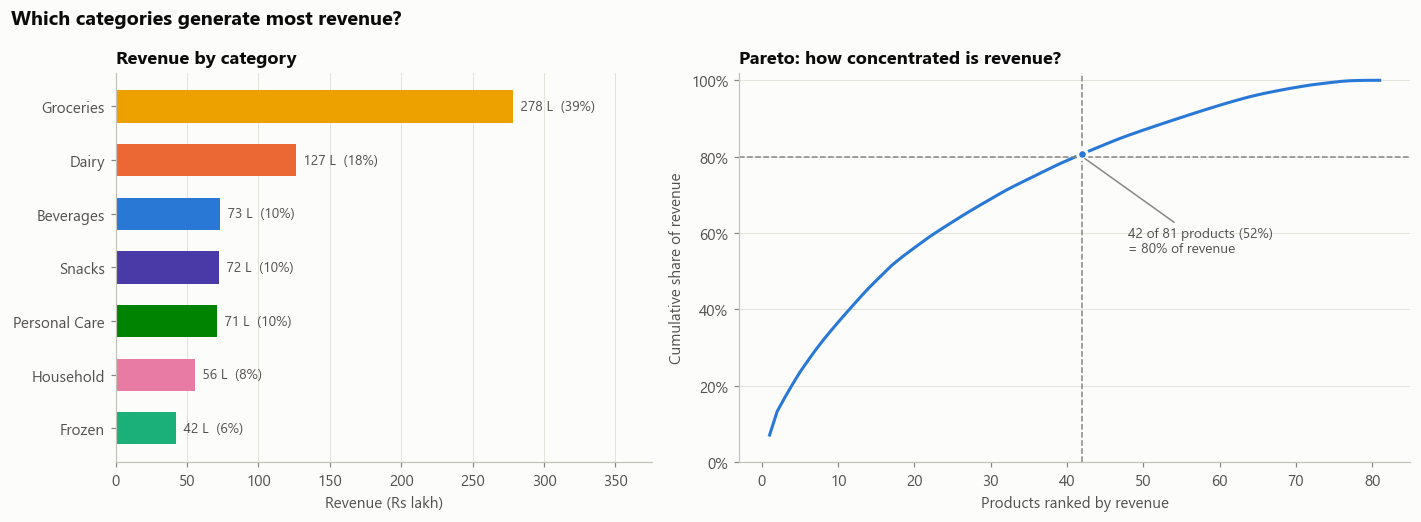

**Insight:** Groceries (39%) and Dairy (18%) bring in 56% of revenue; Frozen is smallest (6%). Revenue is NOT a classic 80/20 pattern - it is spread widely: it takes 42 of 81 products (52%) to reach 80%, although the top 10 alone give 37%. Top products: Ponni Rice 5kg, Milk 1L, Sunflower Oil 1L, Ghee 500ml, Idli Batter 1kg. Action: the top 10 deserve the tightest availability targets and daily stock checks, but a broad range matters, so replenishment must work for the whole catalogue, not only a few hero SKUs.

,revenue,share
category,,
Groceries,27844081.00,0.387096
Dairy,12657266.85,0.175965
Beverages,7295812.00,0.101428
Snacks,7211702.00,0.100259
Personal Care,7130022.00,0.099123
Household,5561891.80,0.077323
Frozen,4229956.00,0.058806


In [12]:
r = results[0]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

### 4.2 Which stores are growing or declining?

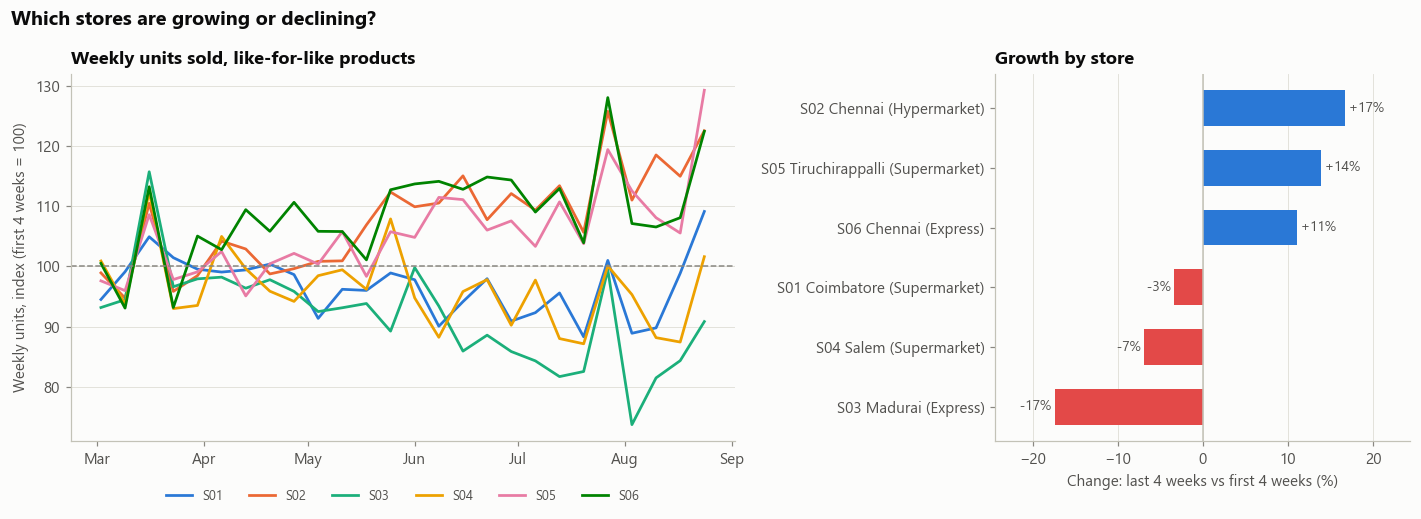

**Insight:** Like-for-like weekly units (last 4 weeks vs first 4): fastest growth S02 (+17%), then S05 (+14%); weakest S03 (-17%). Action: reorder levels set on old sales under-stock growing stores and over-stock declining ones - growth must be a forecasting feature, and S03's stock should be trimmed.

,growth_last4_vs_first4,trend_per_week_pct_of_mean
store_id,,
S03,-0.174113,-0.796688
S04,-0.068672,-0.345699
S01,-0.033315,-0.185476
S06,0.110582,0.528200
S05,0.138686,0.659233
S02,0.167704,0.790895


In [13]:
r = results[1]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

### 4.3 Do promotions increase units sold?

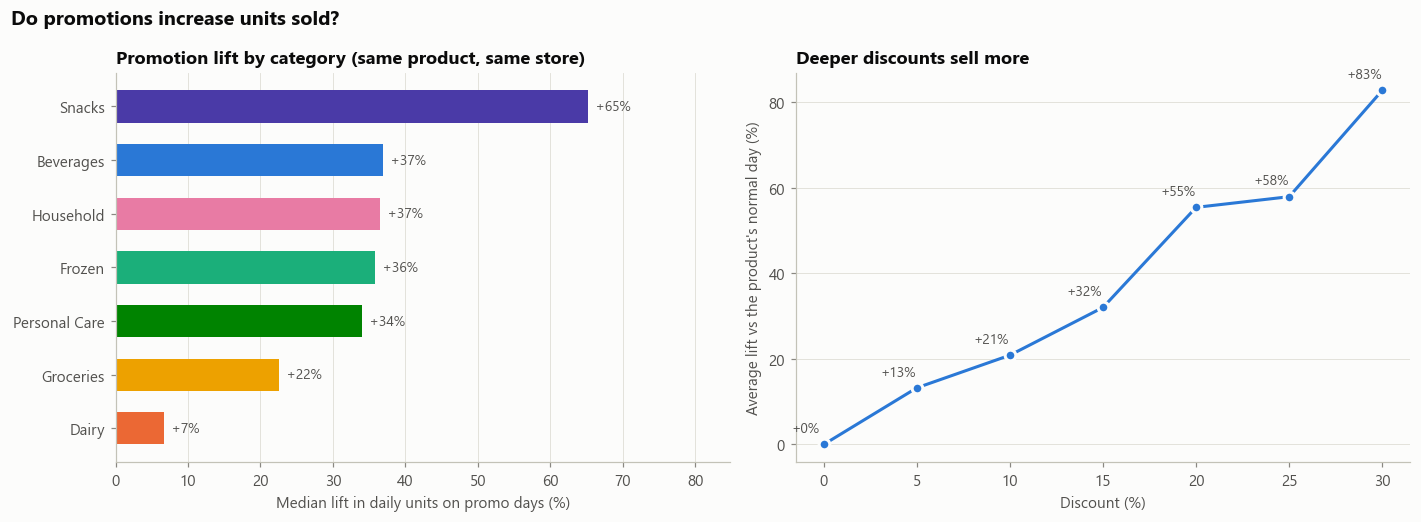

**Insight:** Yes. For the same product in the same store, promo days sell a median +29% more units (93% of 375 store-product pairs gain). Lift is highest in Snacks (+65%) and lowest in Dairy (+7%); it rises with discount depth (5% off: +13%, 30% off: +83%). But the stock-out rate is 13.6% on promo days vs 5.2% otherwise - promotions are not being stocked for. Action: raise the order before every planned promotion by the category's expected lift.

,median_lift
category,
Snacks,0.652199
Beverages,0.368635
Household,0.365517
Frozen,0.358373
Personal Care,0.339943
Groceries,0.224965
Dairy,0.066850


In [14]:
r = results[2]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

### 4.4 How does weekend behaviour differ?

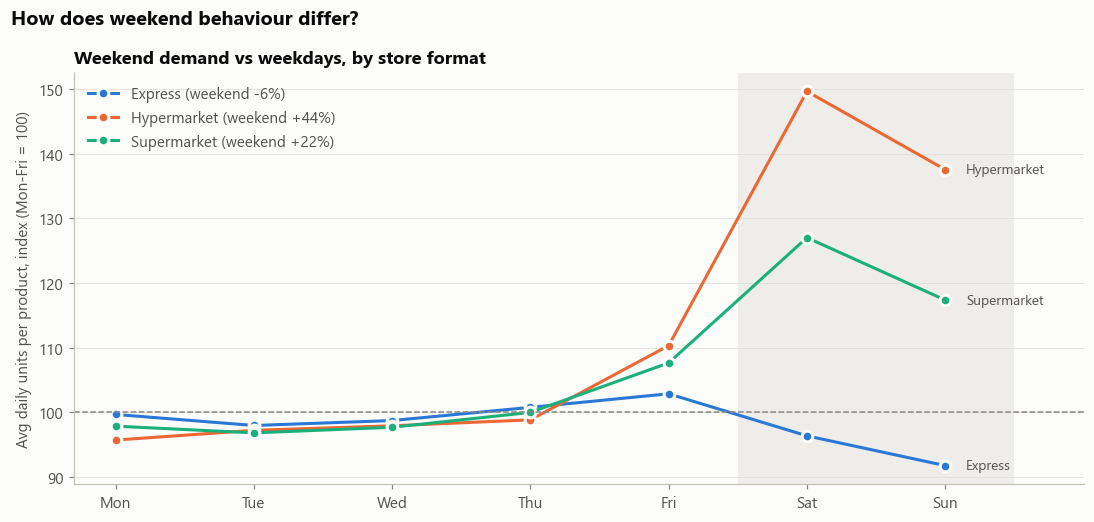

**Insight:** The weekend effect depends on the format: Hypermarket +44%, Supermarket +22%, Express -6% vs weekdays (peak day: Express Fri, Hypermarket Sat, Supermarket Sat). Action: hypermarket/supermarket deliveries should land by Friday; a single weekly pattern for all stores would be wrong.

,weekend_uplift
store_type,
Express,-0.059356
Hypermarket,0.435672
Supermarket,0.221777


In [15]:
r = results[3]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

### 4.5 Which products are volatile? (coefficient of variation / rolling std)

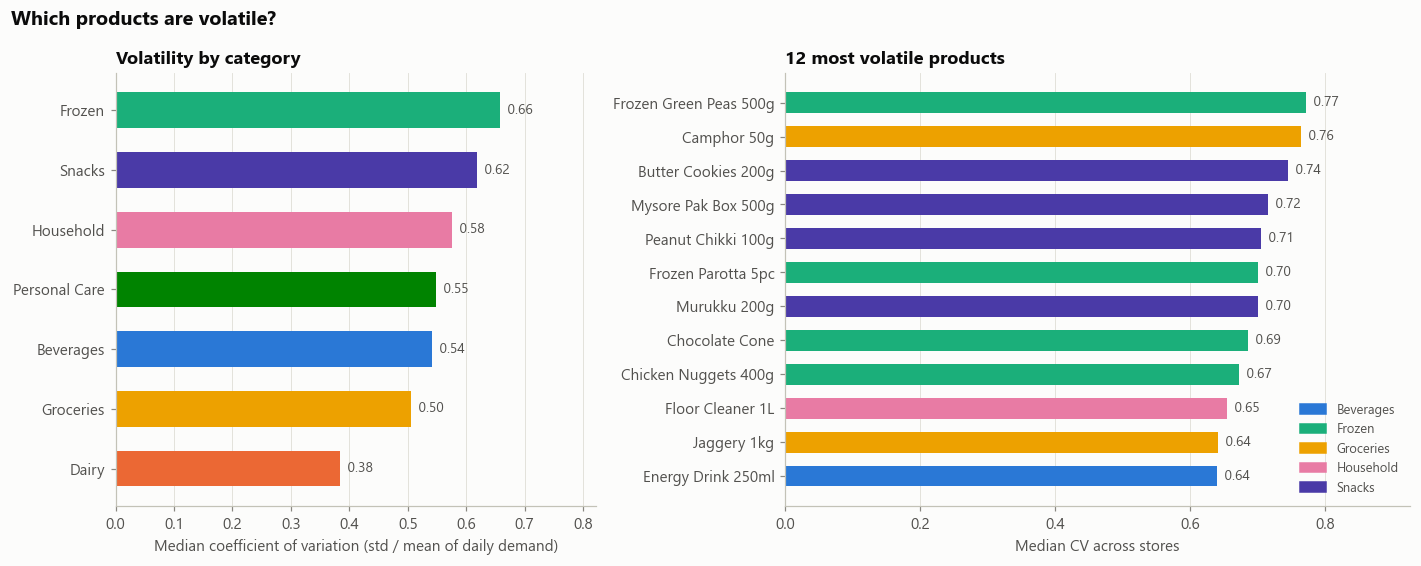

**Insight:** Frozen is the most volatile category (median CV 0.66) and Dairy the most stable (0.38). Most volatile products: Frozen Green Peas 500g, Camphor 50g, Butter Cookies 200g. Part of this is size: slow sellers look volatile from counting noise (Spearman rho between mean demand and CV = -0.65). Volatile beyond what their size explains: Potato Chips 52g at S02, Cola 750ml at S02, Packaged Water 1L at S02. Action: safety stock must scale with each product's volatility, not a flat percentage.

,store_id,product_id,product_name,category,mean_daily,std_daily,avg_rolling_std_7,cv,expected_cv,excess_cv
185,S03,P515,Camphor 50g,Groceries,0.940217,1.155510,0.988362,1.228982,1.031302,1.191680
369,S06,P515,Camphor 50g,Groceries,1.152174,1.168201,1.032191,1.013911,0.931625,1.088325
184,S03,P513,Rava 1kg,Groceries,1.956522,1.668827,1.536048,0.852956,0.714920,1.193079
183,S03,P512,Chilli Powder 200g,Groceries,1.728261,1.422714,1.363464,0.823206,0.760668,1.082213
297,S05,P450,Butter Cookies 200g,Snacks,4.722826,3.864412,3.277074,0.818242,0.460150,1.778208
178,S03,P507,Groundnut Oil 1L,Groceries,2.173913,1.771719,1.577698,0.814991,0.678233,1.201638
294,S05,P447,Murukku 200g,Snacks,6.434783,5.206772,4.379413,0.809161,0.394215,2.052587
358,S06,P503,Wheat Atta 5kg,Groceries,1.972826,1.573108,1.470998,0.797388,0.711960,1.119990
375,S06,P702,Chocolate Cone,Frozen,9.440217,7.461868,5.866726,0.790434,0.325469,2.428603
174,S03,P503,Wheat Atta 5kg,Groceries,1.663043,1.312214,1.252470,0.789044,0.775440,1.017543


In [16]:
r = results[4]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

### 4.6 Which stores repeatedly stock out? (heatmap store x category)

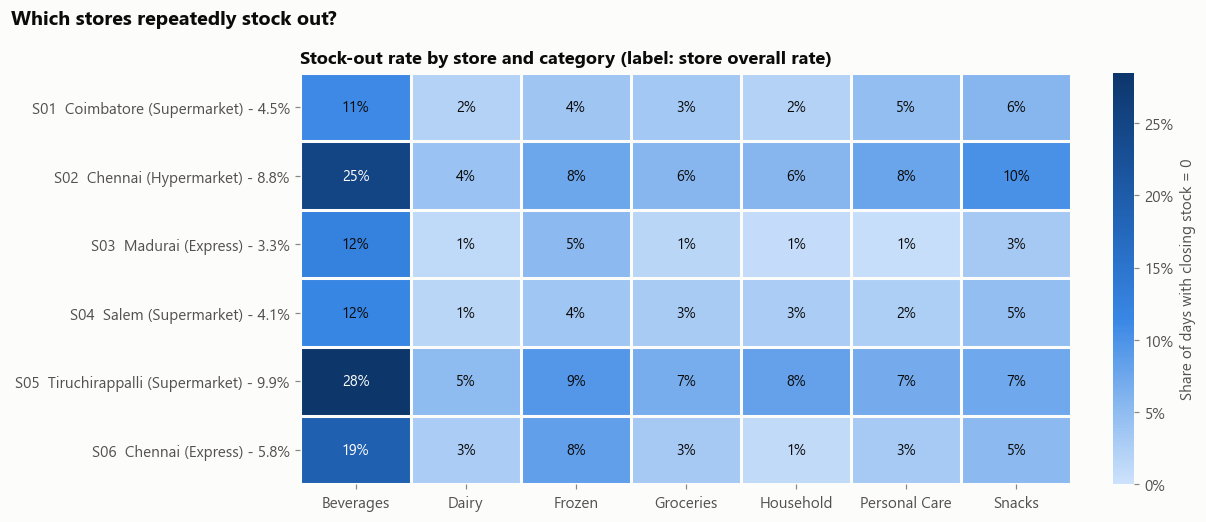

**Insight:** Stock-outs are concentrated: worst store S05 (9.9%) and S02 (8.8%) vs best S03 (3.3%). Beverages stock out on 18% of days - 3.8x the other categories' average. Worst cells: S05-Beverages 28%, S02-Beverages 25%, S06-Beverages 19%. Action: Beverages needs a supply fix (see supplier chart), not just higher reorder levels.

category,Beverages,Dairy,Frozen,Groceries,Household,Personal Care,Snacks
store_id,,,,,,,
S01,0.110846,0.020531,0.036957,0.032609,0.020963,0.046584,0.055854
S02,0.250894,0.040939,0.076087,0.055901,0.055978,0.076965,0.101662
S03,0.124224,0.012228,0.051630,0.014795,0.007246,0.005435,0.031832
S04,0.115614,0.014493,0.035870,0.029762,0.027950,0.024845,0.046187
S05,0.284863,0.050121,0.093478,0.067029,0.081522,0.069876,0.073577
S06,0.190994,0.027174,0.084239,0.032005,0.010870,0.030797,0.051242


In [17]:
r = results[5]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

### 4.7 Are some suppliers causing stock-outs? (extra)

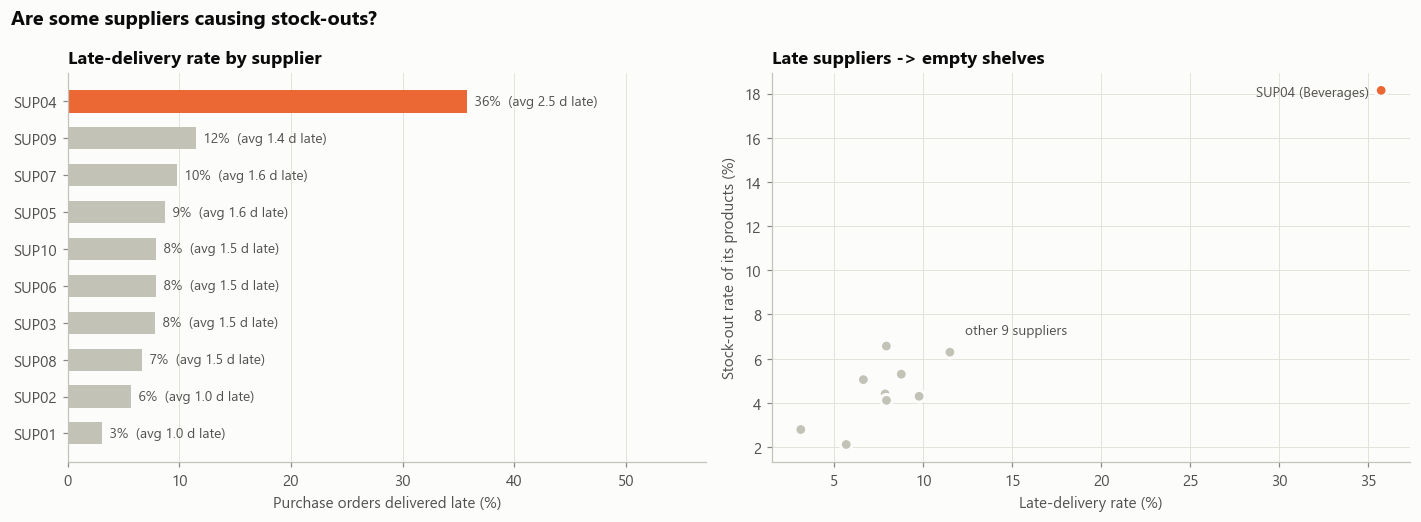

**Insight:** SUP04 (Beverages) delivers 36% of orders late vs 7% for all other suppliers, and its products stock out on 18% of days vs 5% average for the rest. Action: plan SUP04 orders on its real (longer) lead time, hold extra safety stock and escalate with the supplier.

,late_rate,avg_days_late,fill_rate,orders,categories,stockout_rate
supplier_id,,,,,,
SUP01,0.031276,1.000000,0.991177,2430,Dairy,0.027891
SUP02,0.056809,1.000000,0.983794,1197,Groceries,0.021135
SUP08,0.066429,1.464286,0.990966,843,Personal Care,0.050492
SUP03,0.078652,1.490683,0.987821,2047,Groceries,0.044047
SUP06,0.079339,1.500000,0.993801,605,Snacks,0.065681
SUP10,0.079422,1.500000,0.988448,277,"Groceries, Household",0.041101
SUP05,0.087719,1.560000,0.987847,855,"Groceries, Snacks",0.052950
SUP07,0.097744,1.553846,0.984021,665,Household,0.042952
SUP09,0.115031,1.413333,0.984715,652,Frozen,0.062918


In [18]:
r = results[6]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

### 4.8 Why do the same products keep stocking out? (extra - censored demand)

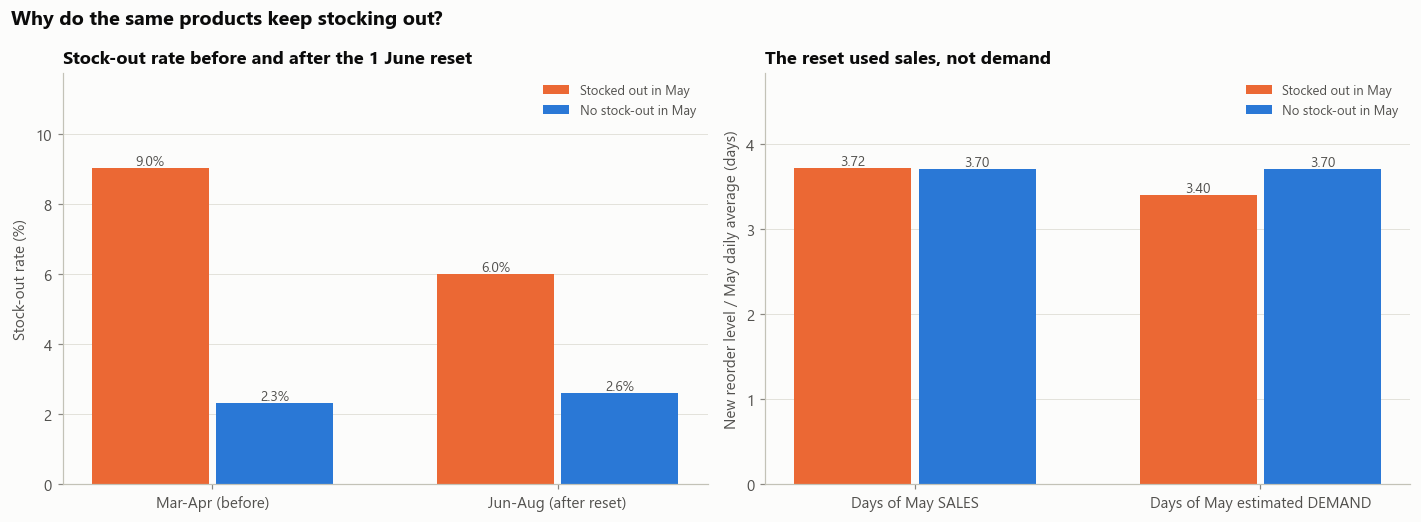

**Insight:** On 1 June every reorder level was reset to about 3.7 days of May *sales* - one rule for all. For products that ran out in May, sales were capped by the empty shelf, so the new level covers only 3.40 days of estimated demand vs 3.70 for the rest. Their levels did rise (median +23%) and stock-outs fell from 9.0% to 6.0% - but they still stock out 2.3x as often as the rest (2.6%). The fix under-corrected because it was based on sales. (Our demand estimate is conservative, so the true shortfall in cover is larger.) Action: plan from estimated demand (demand_est), never from raw sales.

,stockout_rate Mar-Apr (before),stockout_rate Jun-Aug (after reset),days_of_sales,days_of_demand,median_level_change
censored_in_may,,,,,
0.0,0.023263,0.026087,3.701493,3.701493,0.000000
1.0,0.090345,0.060022,3.717438,3.401595,0.228288


In [19]:
r = results[7]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

### 4.9 Where is revenue being lost to empty shelves? (extra)

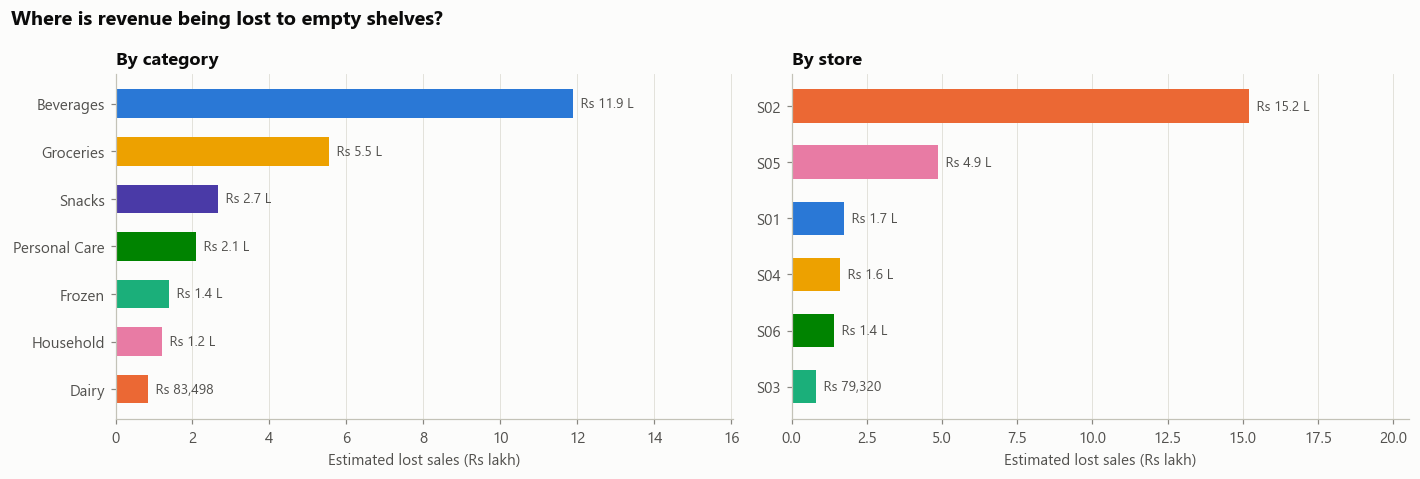

**Insight:** Estimated lost sales: Rs 25.6 L over 6 months (3.6% of revenue) - a conservative figure, because demand beyond an empty shelf is only partly visible. Beverages alone accounts for 46%; S02 is the store losing most (Rs 15.2 L). Action: prioritise the action list by rupees at risk, not by alphabetical order or probability alone.

,lost_sales_by_category
category,
Beverages,1188817.25
Groceries,554909.00
Snacks,265990.25
Personal Care,209600.00
Frozen,138467.00
Household,121454.70
Dairy,83498.15


In [20]:
r = results[8]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

### 4.10 Does heat drive beverage demand? (extra)

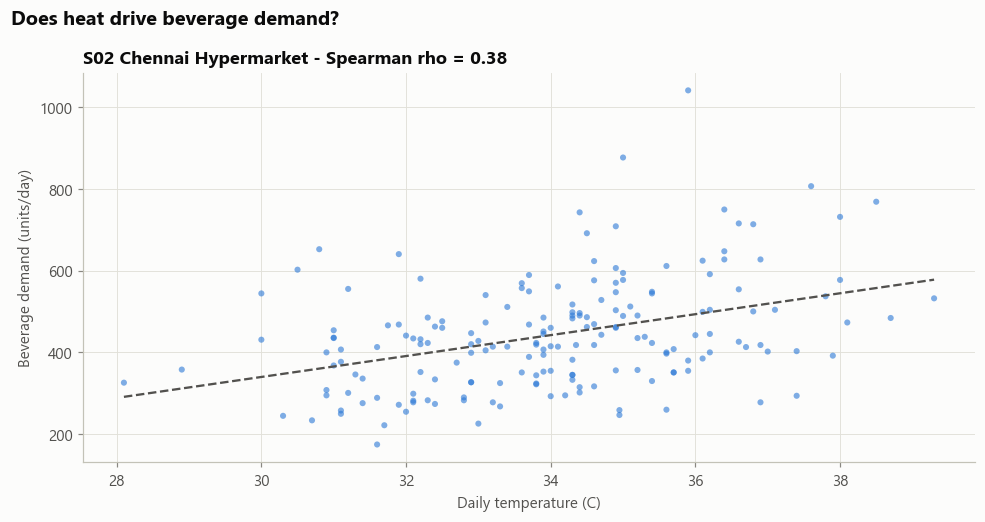

**Insight:** Yes - in S02, each extra degree adds about 26 beverage units a day (rho = 0.38). Beverage stock-outs peak in May (22% of days); Chennai is hottest in June (36.2 C). Action: include the weather forecast in beverage orders (see test T4 for all stores).

In [21]:
r = results[9]
display(r["fig"])
display(Markdown("**Insight:** " + r["insight"]))
r["table"]

## 5. Statistical reasoning
The brief asks for at least 3 tests, each with business question, H0, H1, test, p-value and interpretation. We run the 3 required ones plus 4 that support the recommendation logic.

The test choice follows the data: daily unit counts are skewed, so we use rank-based tests, and comparisons are **paired within the same store x product** wherever possible so that product mix cannot fake an effect. With ~70k rows almost everything is "significant", so **effect sizes** are reported and interpreted.

In [22]:
rows, details = eda_stats.run_tests(m, po)
summary = pd.DataFrame(rows)[["id", "question", "test", "p_value", "effect", "conclusion"]]
summary.assign(p_value=summary.p_value.map(eda_stats.fmt_p))

,id,question,test,p_value,effect,conclusion
0,T1,Do promotions significantly increase sales?,"Wilcoxon signed-rank, paired by store x product (+ per category, Bonferroni)",6.77e-57,median lift +29%; rank-biserial r = 0.94; 93% of pairs gain,Reject H0
1,T2,Does mean demand differ across store types?,"Kruskal-Wallis + pairwise Mann-Whitney (Bonferroni); robustness: Friedman (product as block), ANOVA on log demand",3.03e-27,"epsilon^2 = 0.42; median units/day: Express 5.7, Hypermarket 36.6, Supermarket 10.4",Reject H0
2,T3,Is stock-out frequency associated with promotion status?,"Chi-square test of independence (2x2) + odds ratio, Cramer's V; Mantel-Haenszel by store x category",8.39e-216,stock-out rate 13.6% (promo) vs 5.2%; OR = 2.90; Cramer's V = 0.119; MH-adjusted OR = 3.01,Reject H0
3,T4,Does temperature drive beverage demand?,"Spearman rank correlation, within each store (Bonferroni over 6 stores)",8.39e-06,rho ranges 0.32 to 0.53; significant in 6/6 stores,Reject H0
4,T5,Is late delivery associated with the supplier?,Chi-square test of independence (10 x 2) + odds ratio for the worst supplier vs the rest,2.28e-226,SUP04 late 36% vs 7% others; OR = 7.7; Cramer's V = 0.32,Reject H0
5,T6,Do products that ran out in May keep running out after the June reorder recalibration?,Mann-Whitney U on combination-level Jun-Aug stock-out rates,2.92e-09,mean Jun-Aug stock-out rate 6.0% vs 2.6% (Mar-Apr: 9.0% vs 2.3%); rank-biserial r = 0.38,Reject H0
6,T7,Is weekend demand different from weekday demand?,"Wilcoxon signed-rank, paired by store x product, overall and per store format (Bonferroni)",2.48e-41,"median weekend uplift: Express -6%, Hypermarket +45%, Supermarket +23%",Reject H0


In [23]:
for r in rows:
    display(Markdown(
        f"#### {r['id']}. {r['question']}\n"
        f"- **H0:** {r['H0']}\n- **H1:** {r['H1']}\n"
        f"- **Test:** {r['test']} - *{r['why']}*\n"
        f"- **Result:** {r['statistic']}, p = {eda_stats.fmt_p(r['p_value'])}, {r['effect']} -> **{r['conclusion']}**\n"
        f"- **Interpretation:** {r['interpretation']}\n"
        f"- **Manager action:** {r['action']}"))
    if r["id"] in details:
        display(details[r["id"]])

#### T1. Do promotions significantly increase sales?
- **H0:** For the same store x product, median daily units on promo days = on non-promo days
- **H1:** Median daily units are higher on promo days (one-sided)
- **Test:** Wilcoxon signed-rank, paired by store x product (+ per category, Bonferroni) - *Pairing compares a product with itself, so the mix of which products get promoted cannot fake a lift; daily unit counts are skewed, so a rank test is safer than a t-test.*
- **Result:** W = 68,548, p = 6.77e-57, median lift +29%; rank-biserial r = 0.94; 93% of pairs gain -> **Reject H0**
- **Interpretation:** Promotions raise units sold, and the effect is large (median +29%). Significant in 7/7 categories after Bonferroni: Snacks, Beverages, Household, Frozen, Personal Care, Groceries, Dairy. Strongest: Snacks (+65%).
- **Manager action:** Every planned promotion must increase that week's order by the category lift; promotion days are a required forecasting feature.

,category,pairs,median_lift,p_value,p_bonferroni
6,Snacks,55,0.652199,5.852738e-11,4.096916e-10
0,Beverages,50,0.368635,6.217249e-15,4.352074e-14
4,Household,37,0.365517,7.275958e-12,5.093170e-11
2,Frozen,26,0.358373,2.980232e-08,2.086163e-07
5,Personal Care,36,0.339943,1.455192e-11,1.018634e-10
3,Groceries,120,0.224965,4.179261e-20,2.925483e-19
1,Dairy,51,0.066850,5.717858e-04,4.002501e-03


#### T2. Does mean demand differ across store types?
- **H0:** Daily demand per product has the same distribution in Express, Supermarket and Hypermarket stores
- **H1:** At least one store type differs
- **Test:** Kruskal-Wallis + pairwise Mann-Whitney (Bonferroni); robustness: Friedman (product as block), ANOVA on log demand - *Three groups and skewed demand -> rank test. Restricted to the 48 products sold in ALL formats, so differences in assortment cannot create a false difference.*
- **Result:** H = 122.1, p = 3.03e-27, epsilon^2 = 0.42; median units/day: Express 5.7, Hypermarket 36.6, Supermarket 10.4 -> **Reject H0**
- **Interpretation:** Store format matters a lot: a Hypermarket sells 6.4x an Express store's volume of the same product. Pairwise (Bonferroni): Express vs Hypermarket p=1.44e-19; Express vs Supermarket p=8.24e-09; Hypermarket vs Supermarket p=7.92e-19. Friedman p = 1.43e-21, ANOVA(log) p = 2.21e-41 - same conclusion.
- **Manager action:** Reorder levels and safety stock must be set per store (format), never copied across stores; store_type is a required model feature.

,pair,U,p_value,p_bonferroni
0,Express vs Hypermarket,140.0,4.788023e-20,1.436407e-19
1,Express vs Supermarket,3778.5,2.747487e-09,8.242462e-09
2,Hypermarket vs Supermarket,6451.5,2.641638e-19,7.924915e-19


#### T3. Is stock-out frequency associated with promotion status?
- **H0:** Stock-out status is independent of promotion status
- **H1:** Stock-out status depends on promotion status
- **Test:** Chi-square test of independence (2x2) + odds ratio, Cramer's V; Mantel-Haenszel by store x category - *Both variables are binary. With ~70k rows any tiny difference is 'significant', so the odds ratio is what we interpret. Mantel-Haenszel checks that it is not just because promoted products are in stock-out-prone stores/categories.*
- **Result:** chi2 = 983.1 (df = 1), p = 8.39e-216, stock-out rate 13.6% (promo) vs 5.2%; OR = 2.90; Cramer's V = 0.119; MH-adjusted OR = 3.01 -> **Reject H0**
- **Interpretation:** Promotion days have 2.9x the odds of a stock-out (3.0x after adjusting for store and category, MH p = 5.75e-216). Cramer's V is small because stock-outs are rare overall, but the business effect is large: stores are not ordering for promotions.
- **Manager action:** Link the promotions calendar to replenishment: raise stock before a promotion starts; promo_days_next_7 is a key stock-out feature.

#### T4. Does temperature drive beverage demand?
- **H0:** No monotonic association between daily temperature and beverage demand (rho = 0)
- **H1:** rho != 0
- **Test:** Spearman rank correlation, within each store (Bonferroni over 6 stores) - *The relation need not be linear; testing within a store removes store-size differences.*
- **Result:** median rho = 0.42, p = 8.39e-06, rho ranges 0.32 to 0.53; significant in 6/6 stores -> **Reject H0**
- **Interpretation:** Hotter days sell more beverages in every store (strongest S01, rho = 0.53). p-value shown is the largest (weakest) of the six stores. Temperature also moves with season, so part of this is the summer effect.
- **Manager action:** Use the temperature forecast for beverage and frozen orders in summer.

,store_id,rho,p_value,p_bonferroni
0,S01,0.528656,1.225083e-14,7.350500e-14
1,S02,0.382774,8.210030e-08,4.926018e-07
2,S03,0.350765,1.052390e-06,6.314343e-06
3,S04,0.463405,3.492305e-11,2.095383e-10
4,S05,0.321839,8.389589e-06,5.033753e-05
5,S06,0.473478,1.138528e-11,6.831166e-11


#### T5. Is late delivery associated with the supplier?
- **H0:** Late delivery rate is the same for all 10 suppliers
- **H1:** Late delivery rate differs by supplier
- **Test:** Chi-square test of independence (10 x 2) + odds ratio for the worst supplier vs the rest - *Categorical supplier vs binary late/on-time outcome.*
- **Result:** chi2 = 1,078.3 (df = 9), p = 2.28e-226, SUP04 late 36% vs 7% others; OR = 7.7; Cramer's V = 0.32 -> **Reject H0**
- **Interpretation:** SUP04 is the outlier: 7.7x the odds of a late delivery. This explains why its category stocks out most.
- **Manager action:** Use SUP04's effective lead time (nominal + average delay) in reorder calculations and raise it with the supplier.

#### T6. Do products that ran out in May keep running out after the June reorder recalibration?
- **H0:** Jun-Aug stock-out rate is the same for combinations that stocked out in May and those that did not
- **H1:** It is higher for combinations that stocked out in May (one-sided)
- **Test:** Mann-Whitney U on combination-level Jun-Aug stock-out rates - *One value per store x product avoids treating 90 correlated days as independent; rates are skewed and many are 0.*
- **Result:** U = 19,759, p = 2.92e-09, mean Jun-Aug stock-out rate 6.0% vs 2.6% (Mar-Apr: 9.0% vs 2.3%); rank-biserial r = 0.38 -> **Reject H0**
- **Interpretation:** Stock-outs are chronic: the combinations that ran out in May kept running out after the 1 June reset. The reset set levels from May sales, which were capped by empty shelves, so it under-corrected (see EDA chart 8 for the cover in days of sales vs days of estimated demand).
- **Manager action:** Recalibrate reorder levels on estimated demand (demand_est), and review every combination that stocked out in May.

#### T7. Is weekend demand different from weekday demand?
- **H0:** For the same store x product, median daily units on weekends = on weekdays
- **H1:** They differ (two-sided)
- **Test:** Wilcoxon signed-rank, paired by store x product, overall and per store format (Bonferroni) - *Paired within product, skewed counts.*
- **Result:** W = 7,115, p = 2.48e-41, median weekend uplift: Express -6%, Hypermarket +45%, Supermarket +23% -> **Reject H0**
- **Interpretation:** The weekend effect is real but its size depends on the format: Express p=2.76e-06; Hypermarket p=7.39e-14; Supermarket p=2.17e-34.
- **Manager action:** Deliveries should arrive before the weekend peak in the formats that have one; weekend days in the next 7 is a forecasting feature.

,store_type,pairs,median_uplift,p_value,p_bonferroni
0,Express,96,-0.062851,9.213023e-07,2.763907e-06
1,Hypermarket,77,0.454961,2.462831e-14,7.388492e-14
2,Supermarket,204,0.230160,7.238253e-35,2.171476e-34


## 6. Summary and hand-off to Round 2

**What the data says**
1. Stock-outs are not random: they concentrate in Beverages (supplier SUP04 is late on over a third of its orders), in the growing / under-planned stores S02 and S05, and on promotion days (about 3x the odds).
2. Planning from sales is self-defeating: the 1 June reorder reset was based on sales capped by empty shelves, so it under-corrected and the products that ran out kept running out.
3. Demand has strong, predictable drivers: promotions (+29% median, rising with discount depth), store format (a hypermarket sells ~6x an express store of the same product), weekends (format-specific), temperature (beverages) and store growth trends.

**Hand-off to Student 2 (features & forecasting)**
- Use `data/processed/master_dataset.csv`; build the target from `demand_est`, not `units_sold`.
- Future-window promotion features must come from `promotions_daily.csv` (runs to 7 Sep), not from future transactions.
- `external_factors_clean.csv` runs to 7 Sep: calendar columns are known in advance; treat future weather as a forecast.
- `sparse_history_flag` marks the 4 late launches; their lag features will be empty.

**Hand-off to Student 3 (classification & recommendation)**
- Stock-out label: `stockout_flag` (closing stock = 0). Incoming stock: OPEN rows of `purchase_orders_clean.csv`.
- Supplier reliability (late rate, average delay) is in the table under section 4.7 - use it for the effective lead time.
- Rank actions by rupees: `lost_sales_est` shows where empty shelves cost most.